# Lesson 5. Several Spots: Color, Opacity, and Overlap

[Course plan](../../README.md) · [Previous lesson](lesson-04.ipynb) · [Русский](../ru/lesson-05.ipynb)

We can already move, stretch, and rotate one spot. We'll add another. At an overlap, the program needs one pixel color. The two RGB triples alone do not settle it: each spot may have a different opacity, and their order also matters.

We'll start with two spots on a white background and swap their places in a list. The image changes even though their positions, sizes, and colors stay the same. We'll find out why and calculate one pixel by hand.

A small editor lets us add spots and change their shape, color, opacity, and order. We'll save the scene as JSON so we can return to it. For now, we choose every parameter by hand. In the next block, we'll begin asking the program to do that work.

## 1. Two Spots in Reverse Order

In the first image, the red spot is in front of the blue one. In the second, the order is reversed. The right panel shows the difference: black means identical, brighter areas mean a larger change.

For now, “front” and “back” mean **the order in a list**, which we choose ourselves. There is no 3D camera or depth calculation here. The first list item is the front layer.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
import numpy as np
from IPython.display import display

course_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "mixing_demos.py").is_file()), None
)
if course_root is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from gaussian_math import composite_at, load_scene_json
from mixing_demos import (
    overlap_figure, alpha_figure, pixel_figure, editor_figure,
    preset_scene, gaussian_editor,
)
LANG = 'en'

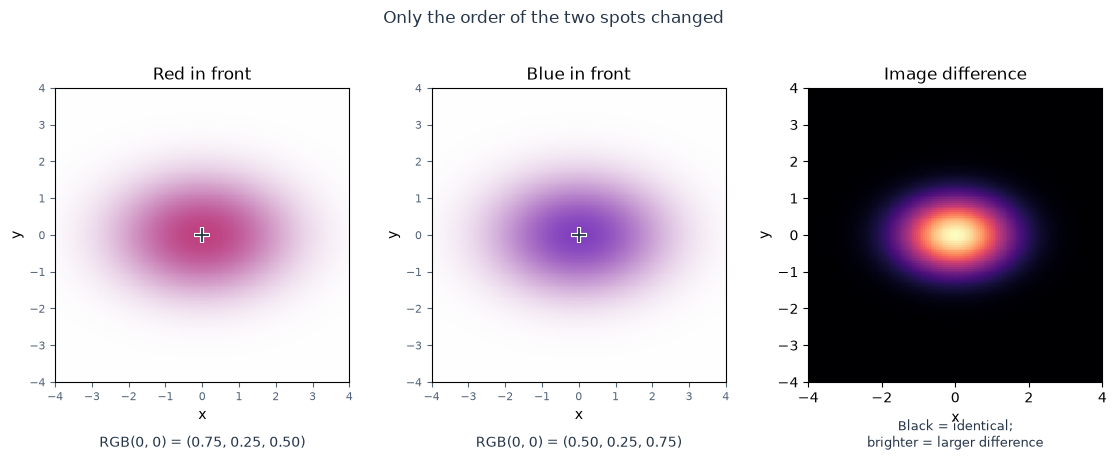

In [2]:
display(overlap_figure(language=LANG))
editor = gaussian_editor(language=LANG)
display(editor)

The **“Reset all”** button restores two spots centered at `(0, 0)`, with scales `1.5` and `1`, no rotation, and opacity `0.5` each. The background is white, and the cross is at the center.

This scene makes four different changes easy to see:

1. With the red spot selected, **“One layer back”** reverses the overlap order. Its parameters stay the same, but the center color changes. **“One layer forward”** restores the original order.
2. When red's opacity falls to zero, its color disappears. The dashed outline remains while the selected-spot contour is enabled: it is an editor guide, not part of the image.
3. We'll restore opacity to `0.5` and move red horizontally. Its influence now differs from pixel to pixel. The weights and color contributions change in the table below the image.
4. After **“Reset all,”** changing only **“Pixel x”** moves the cross and calculation while the spots stay in place.

We already have a colored image. Now we can take apart the numbers that produced it.

## 2. A Color Is Three Numbers

We'll use three channels: **R** for red, **G** for green, and **B** for blue. Each stores a number from 0 to 1. We can write the three together:

$$
c=(r,g,b).
$$

$c$ is the whole color; $r,g,b$ are its components in that order. The parentheses group them into one value. These numbers have no physical units and are not point coordinates. Below, an uppercase $G$ denotes a Gaussian's weight; a lowercase $g$ denotes the green **channel**.

| Color | RGB | How to read it |
|---|---|---|
| Red | `(1, 0, 0)` | Full red channel; the others are zero |
| Blue | `(0, 0, 1)` | Full blue channel |
| White | `(1, 1, 1)` | All three channels are 1 |
| Black | `(0, 0, 0)` | All three channels are 0 |
| Gray | `(0.5, 0.5, 0.5)` | All channels have the same intermediate value |

Multiplying a color by a number means multiplying **each channel**:

$$
0.5(1,0,0)=(0.5\cdot1,\;0.5\cdot0,\;0.5\cdot0)=(0.5,0,0).
$$

Addition also works channel by channel. For example, $(0.5,0,0)+(0,0,0.25)=(0.5,0,0.25)$. Red is added to red, green to green, and blue to blue.

This editor mixes the numeric RGB values as stored and displays the result without a separate gamma-correction step. That gives us a simple way to study overlap. It does not model the physical mixing of light; real image processing also needs to account for how color is encoded.

## 3. Spatial Weight and Opacity Are Different Numbers

In the previous lessons, we calculated $G(x,y)$: the Gaussian's weight at coordinates $x,y$. It is 1 at the center and decreases farther away. The center, scales, and rotation determine its shape.

Now we add **opacity** $o$: one number from 0 to 1 for the whole Gaussian. Here, $o$ is a lowercase letter, not a zero. It lets us weaken the entire spot without moving or stretching it.

Multiplying the two numbers gives the strength of its color contribution at one location:

$$
\alpha(x,y)=o\,G(x,y).
$$

The Greek letter $\alpha$ is called “alpha.” Writing $o\,G$ means ordinary multiplication. We first calculate the spatial weight, then multiply by opacity. Alpha is also dimensionless and lies between 0 and 1.

With $o=0.5$:

- at the center, $G(0,0)=1$, so $\alpha(0,0)=0.5\cdot1=0.5$;
- one scale away along an axis, $G\approx0.606531$, so $\alpha=0.5\exp(-0.5)\approx0.303265$;
- far from the center, a small $G$ gives an even smaller alpha.

We don't need to store a separate alpha for every location. We store one opacity and calculate alpha for each pixel. In the next figure, blue shows the weight; orange shows that weight multiplied by `0.5`.

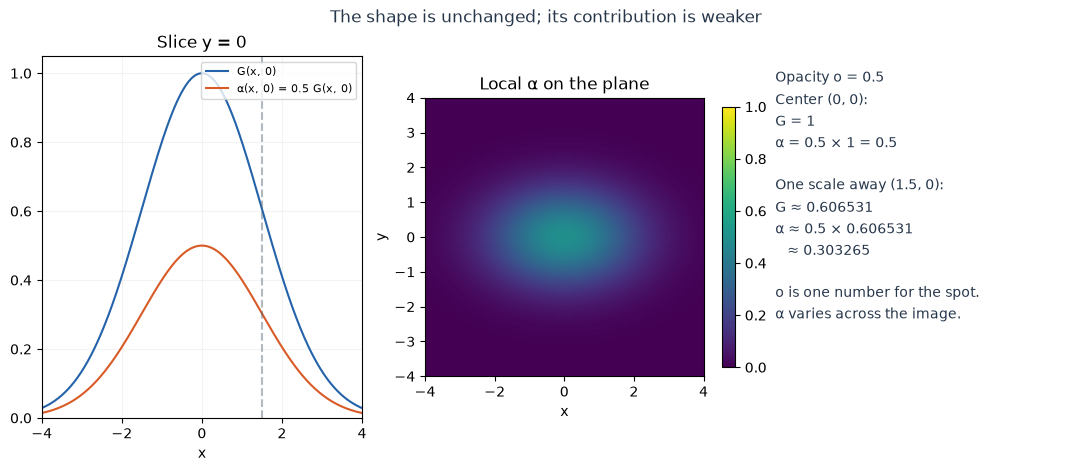

In [3]:
display(alpha_figure(language=LANG))

## 4. One Spot over a Background

With an alpha of `0.5` at the pixel, the shares are equal. Half of the contribution comes from the spot's color; the other half comes from what is behind it. Subtraction gives the remainder: $1-0.5=0.5$.

For one spot over an opaque background:

$$
C=\alpha c+(1-\alpha)B.
$$

$C$ is the resulting pixel RGB, $c$ is the spot's color, and $B$ is the background color. All three are triples. Alpha and $1-\alpha$ are ordinary numbers that multiply each triple. Our background is opaque: nothing shows through from behind it.

For red $c=(1,0,0)$ and a white background $B=(1,1,1)$:

$$
\begin{aligned}
C&=0.5(1,0,0)+(1-0.5)(1,1,1)\\
&=(0.5,0,0)+0.5(1,1,1)\\
&=(0.5,0,0)+(0.5,0.5,0.5)\\
&=(1,0.5,0.5).
\end{aligned}
$$

Red: $0.5+0.5=1$. Green: $0+0.5=0.5$. Blue: $0+0.5=0.5$. We get a light red because the white background still contributes.

With a black background $(0,0,0)$, the background contribution becomes zero, leaving $(0.5,0,0)$. A pixel's RGB therefore depends on more than the spot itself.

## 5. Two Spots: What Is Left for the Next Layer?

We return to the starting scene: red in front, blue behind it, and a white background. Both Gaussians are centered at `(0, 0)`. Their weights there are both 1, so both alphas equal their opacities: `0.5`.

We'll work **from front to back**, keeping track of two values:

- $C$ is the color contribution collected so far. It starts at $(0,0,0)$ because we haven't added anything;
- $T$ is the fraction still available to later layers. It starts at 1 because nothing has blocked any contribution before the first spot.

$T$ stands for the remaining transmittance. It is one number between 0 and 1. Each layer takes its fraction $\alpha$ from the **remaining** $T$, rather than starting again with a whole unit.

### Red comes first

Before it, $T=1$, so we add:

$$
1\cdot0.5\cdot(1,0,0)=(0.5,0,0).
$$

Multiplying $1\cdot0.5$ gives the red layer's share. We then multiply each color channel by that share. The accumulated color is now $C=(0.5,0,0)$.

For everything behind red, the remainder is:

$$
T=1\cdot(1-0.5)=1\cdot0.5=0.5.
$$

### Blue comes next

Its own alpha is also `0.5`, but only `0.5` remains in front of it. Its contribution is therefore:

$$
0.5\cdot0.5\cdot(0,0,1)=0.25(0,0,1)=(0,0,0.25).
$$

Adding it to the color collected so far gives: $(0.5,0,0)+(0,0,0.25)=(0.5,0,0.25)$.

After blue, the remainder is:

$$
T=0.5\cdot(1-0.5)=0.5\cdot0.5=0.25.
$$

### The background comes last

The spot list has ended, but a share of `0.25` remains. It belongs to the white background:

$$
0.25(1,1,1)=(0.25,0.25,0.25).
$$

The three contributions add up to:

$$
\begin{aligned}
C&=(0.5,0,0)+(0,0,0.25)+(0.25,0.25,0.25)\\
&=(0.5+0+0.25,\;0+0+0.25,\;0+0.25+0.25)\\
&=(0.75,0.25,0.5).
\end{aligned}
$$

That is the RGB under the cross after resetting the editor. The green channel is not zero even though both spots have green 0: its `0.25` came from the white background.

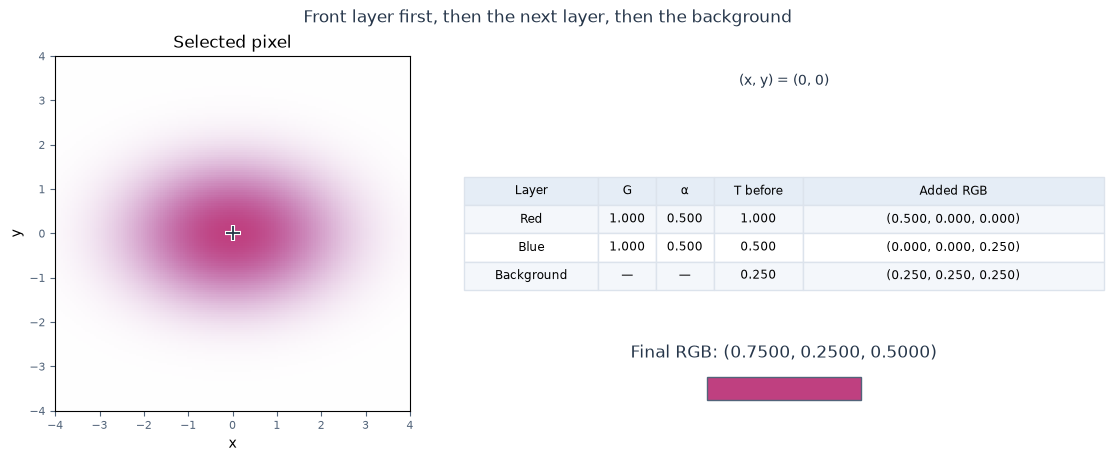

In [4]:
display(pixel_figure(language=LANG))

The same calculation follows directly in code. A NumPy array stores the three channels; multiplication by a number and addition of arrays work component by component, just as we did by hand. `remaining` is our $T$. The lines follow the same order: red, remainder, blue, remainder, background.

In [5]:
red = np.array([1.0, 0.0, 0.0])
blue = np.array([0.0, 0.0, 1.0])
background = np.array([1.0, 1.0, 1.0])
alpha_red = 0.5
alpha_blue = 0.5

remaining = 1.0
from_red = remaining * alpha_red * red
remaining = remaining * (1 - alpha_red)
from_blue = remaining * alpha_blue * blue
remaining = remaining * (1 - alpha_blue)
from_background = remaining * background
pixel = from_red + from_blue + from_background

print("red       ", from_red)
print("blue      ", from_blue)
print("background", from_background)
print("pixel RGB ", pixel)

red        [0.5 0.  0. ]
blue       [0.   0.   0.25]
background [0.25 0.25 0.25]
pixel RGB  [0.75 0.25 0.5 ]


## 6. Why Swapping the Order Changes the Color

We move blue in front of red. The alphas haven't changed, but blue now gets the first share of `0.5`, leaving red a share of `0.25`:

$$
\begin{aligned}
C&=0.5(0,0,1)+0.25(1,0,0)+0.25(1,1,1)\\
&=(0,0,0.5)+(0.25,0,0)+(0.25,0.25,0.25)\\
&=(0.5,0.25,0.75).
\end{aligned}
$$

There is now less red and more blue. The background gets `0.25` in either order because the product of the remaining fractions is the same: $0.5\cdot0.5=0.25$.

For any two spots, the whole calculation is:

$$
C=\alpha_1 c_1+(1-\alpha_1)\alpha_2 c_2+(1-\alpha_1)(1-\alpha_2)B.
$$

Subscripts 1 and 2 refer to positions in the list: the first spot is in front of the second. The first term is the front spot's contribution. The second is the rear spot's contribution after accounting for what the front spot lets through. The last is the background contribution after both layers. These are the same three steps, collected into one line.

An ordinary average of red and blue would give $(0.5,0,0.5)$. It accounts for neither order nor the white background. Averaging two RGB values therefore does not replace this calculation.

Sometimes swapping the order makes no difference: for example, when both colors are identical or one spot has zero alpha at the pixel. But in general, order matters.

## 7. Away from the Center: the Same Calculation

The center was convenient: the spatial weight was 1. Now we move to pixel $(1.5,0)$. Both centers are still $(0,0)$, scales are $(1.5,1)$, and there is no rotation.

First comes the Gaussian calculation from lesson 3:

$$
\begin{aligned}
u&=(1.5-0)/1.5=1,\\
v&=(0-0)/1=0,\\
q&=1^2+0^2=1+0=1,\\
G&=\exp(-q/2)=\exp(-0.5)\approx0.606531.
\end{aligned}
$$

$u,v$ are offsets measured in the scales along the two axes. $q$ is the sum of their squares. Both spots have the same shape and center, so they give the same weight.

Each opacity is `0.5`, so:

$$
\alpha=0.5\exp(-0.5)\approx0.5\cdot0.60653066\approx0.303265.
$$

We then work from red to blue again:

| Step | Share | RGB contribution |
|---|---|---|
| Red | $1\cdot0.303265\approx0.303265$ | $(0.303265,0,0)$ |
| Remaining after red | $1-0.303265\approx0.696735$ | No color added in this step |
| Blue | $0.696735\cdot0.303265\approx0.211295$ | $(0,0,0.211295)$ |
| Remaining after blue | $0.696735(1-0.303265)\approx0.485439$ | This share goes to the background |
| White background | $0.485439$ | $(0.485439,0.485439,0.485439)$ |

Adding the channels gives:

$$
\begin{aligned}
R&\approx0.303265+0.485439\approx0.788705,\\
G_{\text{channel}}&\approx0+0.485439=0.485439,\\
B_{\text{channel}}&\approx0.211295+0.485439\approx0.696735.
\end{aligned}
$$

The final digits come from unrounded values; the text shows six decimal places. The result is approximately `(0.788705, 0.485439, 0.696735)`. Compared with the center, the white background's share has increased from `0.25` to `0.485439`: both spots have weakened toward the edge.

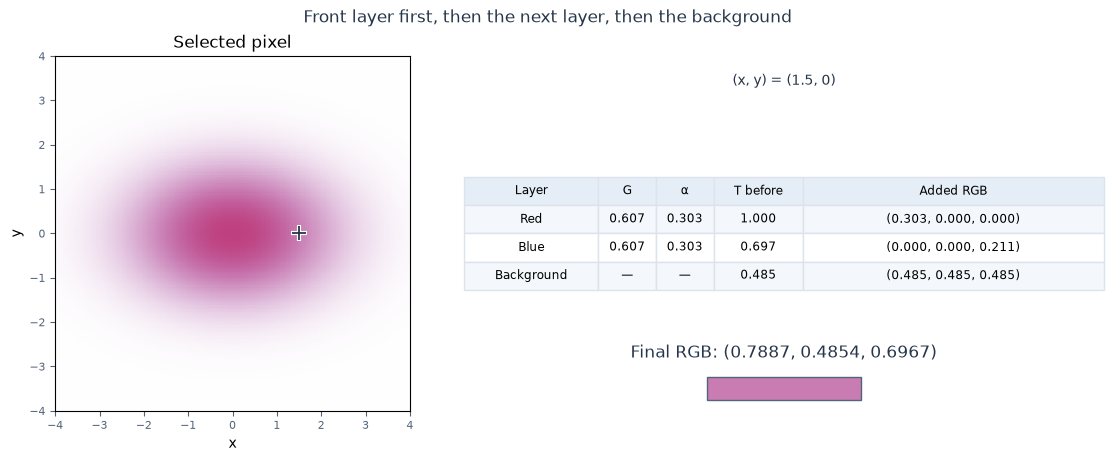

In [6]:
display(pixel_figure(x=1.5, y=0, language=LANG))

## 8. The Same Calculation for Any Number of Spots

The third, tenth, or twentieth spot needs no new rule. At each pixel, we repeat two operations:

$$
\begin{aligned}
C_{\text{new}}&=C_{\text{old}}+T_{\text{old}}\,\alpha_i c_i,\\
T_{\text{new}}&=T_{\text{old}}(1-\alpha_i).
\end{aligned}
$$

The subscript $i$ identifies the current spot. $\alpha_i$ is its alpha **at this pixel**, and $c_i$ is its RGB. We first use the old remainder to calculate the color contribution and add it to the accumulated color. Only then do we update the remainder for the next spot. Reducing $T$ first would incorrectly make the current spot weaken its own contribution.

Before the first spot, $C=(0,0,0)$ and $T=1$. After the last, we add $TB$. That final step also makes an empty scene white on a white background: there are no spots, $T$ is still 1, and the result is $1\cdot B=B$.

Why don't repeated contributions make the color grow without limit? For two spots, the shares add up to:

$$
\begin{aligned}
&\alpha_1+(1-\alpha_1)\alpha_2+(1-\alpha_1)(1-\alpha_2)\\
&=\alpha_1+(1-\alpha_1)\bigl[\alpha_2+(1-\alpha_2)\bigr]\\
&=\alpha_1+(1-\alpha_1)\cdot1=1.
\end{aligned}
$$

In the second line, we factored $1-\alpha_1$ out of the last two terms. Inside the brackets, $\alpha_2+1-\alpha_2=1$. The front spot and the entire remainder then add up to 1 again. Each extra layer divides only the share that remains.

So if alphas and channels lie between 0 and 1, the resulting channels stay in that range too. Our example has especially simple shares: $0.5+0.25+0.25=1$. This is a weighted combination; its weights depend on alphas and order rather than necessarily being equal.

In the next function, the Gaussian shape has already been evaluated. The inputs are alphas for **one** pixel and colors ordered from front to back. Each pair in `alpha_colors` contains one alpha and one RGB triple. The loop repeats the two-line rule, then adds the background.

These stored colors have not already been multiplied by alpha, so we multiply by it exactly once. Passing a color that has already been multiplied by alpha into this function would apply alpha twice and make the contribution too weak.

In [7]:
def blend_one_pixel(alpha_colors, background):
    color = np.zeros(3)
    remaining = 1.0
    for alpha, rgb in alpha_colors:
        color = color + remaining * alpha * np.asarray(rgb)
        remaining = remaining * (1 - alpha)
    return color + remaining * np.asarray(background)

front_red = [(0.5, (1, 0, 0)), (0.5, (0, 0, 1))]
front_blue = list(reversed(front_red))
print("Red in front: ", blend_one_pixel(front_red, (1, 1, 1)))
print("Blue in front:", blend_one_pixel(front_blue, (1, 1, 1)))

Red in front:  [0.75 0.25 0.5 ]
Blue in front: [0.5  0.25 0.75]


## 9. What Happens at the Limits?

**Opacity zero.** Then $\alpha=0\cdot G=0$ at every pixel. The color contribution is zero and the remainder is unchanged: $T(1-0)=T$. Compositing can skip the spot, although its parameters may still exist in the list.

**Opacity one.** At the center, $G=1$, so $\alpha=1$. The remainder becomes $T(1-1)=0$: everything behind that point is hidden. Away from the center, however, $G<1$, so $\alpha=G<1$ and the background contributes again. Setting opacity to `1` does not turn the whole spot into an opaque disk.

**Two spots with opacity 0.5.** Overlapping them does not make them fully opaque. At their common center, the remainder is $T=0.5\cdot0.5=0.25$. The spots therefore occupy a share of $1-T=1-0.25=0.75$. Simply adding `0.5 + 0.5` would be wrong.

**An empty list.** Only the background remains. That is how the “Blank canvas” example works.

**Values outside the range.** RGB and opacity must lie between 0 and 1, inclusive. A negative alpha would give a negative contribution; an alpha above 1 would give a negative remainder. Neither belongs to this model. Spot scales remain positive, as in lessons 3–4.

The mathematical Gaussian's tails do not stop at the dashed contour. The editor displays only the square from −4 to 4 on each axis; the function continues beyond it. Very small values can disappear because of computer precision, as discussed in lesson 2.

## 10. Building a Picture

The editor near the start of the lesson includes a **“Flower”** example. With **“Flower”** selected in **“Example,”** the **“Load example”** button opens a picture made of ten Gaussians: a center, six petals, two leaves, and a stem. Its starting appearance is shown below.

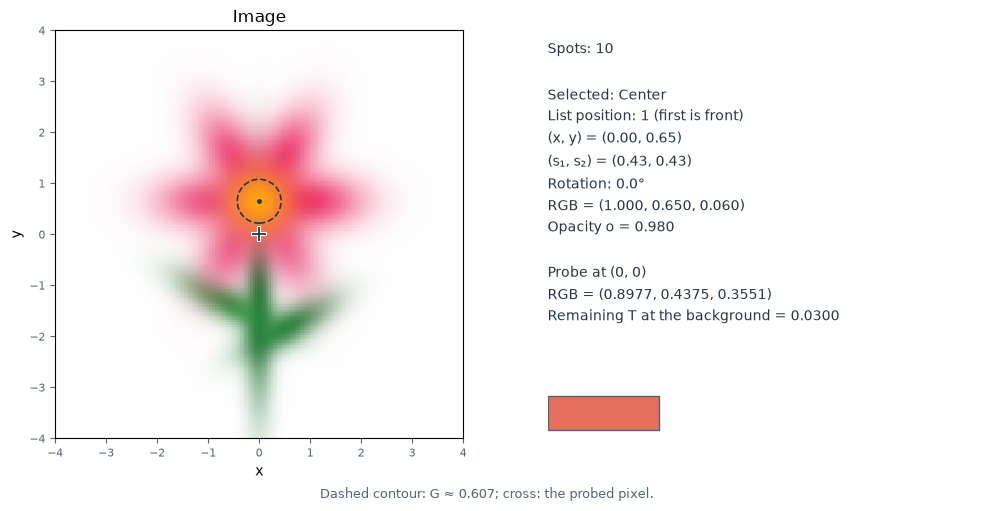

In [8]:
flower_layers, flower_background = preset_scene("flower", language=LANG)
display(editor_figure(flower_layers, flower_background, language=LANG))

Each parameter now corresponds to a specific part of the picture:

| Change | Effect on the image |
|---|---|
| Center `x`, `y` | The spot moves |
| Scales `s₁`, `s₂` | The spot stretches along its own axes |
| Rotation | Those axes rotate with the spot |
| Color | The spot's three RGB channels change |
| Opacity | Its contribution changes across the whole shape |
| List position | Different spots attenuate its contribution |
| Background color | The contribution left after all spots changes |

We'll first lengthen one petal and rotate it. Then we'll move the flower's center behind the petals and compare the result with its earlier position in front. List position can matter more than a color change.

**“Add spot”** inserts a new element at the front. **“Remove spot”** removes the selected one. The ordering buttons move it by one position. The **“Blank canvas”** example leaves only the background, ready for a new picture. **“Reset all”** restores the original red and blue spots, white background, and cross at the center.

The pixel probe uses a `161 × 161` grid. There are 160 intervals between −4 and 4: $(4-(-4))/160=8/160=0.05$. One pixel-slider step is therefore `0.05`, corresponding to the next pixel center. Moving this slider measures the image; it does not move the spots.

The editor supports up to 24 spots. Centers range from −4 to 4, scales from `0.2` to `3`, and angles from −180° to 180°. These are convenient control-panel limits, not new restrictions on the Gaussian formula.

## 11. Saving and Restoring the Scene

The **“Export JSON”** button writes the scene parameters into the text field. A link above it offers `gaussian-scene.json` as a download. The scene can be saved as a file or copied as text.

JSON is a text format for storing data. Our file contains a background color and a list of spots. Each spot stores its name, center, two scales, angle, RGB, and opacity. List order is preserved too: the first item remains in front. These are drawing parameters, not a finished pixel image.

A complete round trip checks that the scene survives saving:

1. We export the scene and keep a copy of its JSON outside the editor.
2. “Reset all” restores the original picture of two spots.
3. The saved JSON goes back into the same text field; **“Import JSON”** restores the scene. A downloaded file contains the same text, which can be pasted into this field.
4. We compare a few parameters and the RGB under the cross with the original scene. With the same probe coordinates, the result matches.

The cross and dashed outline are viewing tools; they are not part of the scene file. Comparing the same pixel therefore means keeping the cross at the same coordinates. Invalid JSON or parameters outside the editor's limits leave the current scene unchanged; a message explains the problem.

The same round trip works in code: we take the editor's **current** state, save it to a string, read it back, and compare pixel `(0, 0)`. The scene stays in memory here; no file is created on disk.

In [9]:
saved_scene = editor.course_export()
restored_layers, restored_background = load_scene_json(saved_scene)
before = composite_at(0, 0, editor.course_state["layers"], editor.course_state["background"])["color"]
after = composite_at(0, 0, restored_layers, restored_background)["color"]
print("Spots:", len(restored_layers))
print("Before:", before)
print("After: ", after)
print("Same pixel:", np.allclose(before, after))

Spots: 2
Before: [0.75 0.25 0.5 ]
After:  [0.75 0.25 0.5 ]
Same pixel: True


## 12. A Few Numerical Checks

### Exercise 1. Red Is Off

The two spots share a center again. Red is in front with opacity `0`; blue has opacity `0.5`. The background is white. What RGB appears at the center?

<details>
<summary>Worked answer</summary>

Red has alpha 0, so it adds nothing and leaves $T=1$. Blue adds $1\cdot0.5(0,0,1)=(0,0,0.5)$. The remainder is $T=1(1-0.5)=0.5$. White contributes $(0.5,0.5,0.5)$. The result is $(0.5,0.5,1)$. Swapping places with a completely disabled red spot changes nothing.

</details>

### Exercise 2. Red Covers the Center

The front red spot now has opacity `1`. What happens at the center? Must blue disappear from the whole image?

<details>
<summary>Worked answer</summary>

At red's center, $G=1$, so $\alpha=1\cdot1=1$. Its contribution is $(1,0,0)$, and the remainder is $T=1(1-1)=0$. Blue and the background get no contribution there, so the result is pure red. Away from the center, $G<1$ and alpha is below 1. The rear spot and background may remain visible there.

</details>

### Exercise 3. A Black Background

Both opacities are `0.5` again, with red in front. The background is now black. What RGB appears at the center?

<details>
<summary>Worked answer</summary>

Red contributes $(0.5,0,0)$ and blue contributes $(0,0,0.25)$. The remaining share is still `0.25`, but it now multiplies black: $0.25(0,0,0)=(0,0,0)$. The result is $(0.5,0,0.25)$. Changing the background did not change the Gaussian weights, alphas, or the front and rear spots' shares.

</details>

### Exercise 4. Why Is Order Sometimes Invisible?

Both spots are red, each with opacity `0.5`, over a white background. Will swapping them change the center color?

<details>
<summary>Worked answer</summary>

In either order, one red spot gets a share of `0.5` and the other gets `0.25`. Their combined contribution is $0.75(1,0,0)=(0.75,0,0)$. The background adds $(0.25,0.25,0.25)$, giving $(1,0.25,0.25)$. The result depends not just on how shares change, but on which colors receive them. Here, both colors are identical.

</details>

### Exercise 5. A Weak Contribution Away from the Center

A spot has opacity `0.8` and weight `0.25` at the probed location. The remaining fraction before it is $T=0.5$. What are its local alpha, its share of the final pixel, and the new remainder?

<details>
<summary>Worked answer</summary>

First, $\alpha=oG=0.8\cdot0.25=0.2$. The spot's final color share is $T\alpha=0.5\cdot0.2=0.1$. The new remainder is $T(1-\alpha)=0.5(1-0.2)=0.5\cdot0.8=0.4$. The spot took `0.1` from the previous `0.5`, leaving `0.4`. Its RGB must be multiplied by `0.1`, not by `0.8` or `0.2`.

</details>

## 13. A Small Project to Finish the Block

For the final experiment, we start with a blank canvas and build a recognizable picture from **6–12 Gaussians**: a flower, fish, glowing lighthouse, or another simple silhouette. This picture starts from scratch, without the flower preset.

Four checks connect the finished scene to the calculations:

1. At least one spot is stretched and rotated. Which axis is longer, and where does it point?
2. Two differently colored spots overlap. We save both orders and compare a pixel where the results differ.
3. We lower one spot's opacity without changing its shape. What happens to $o$, $G$, $\alpha$, and $T$?
4. For a pixel in an overlap, we work through the first two contributions: weight, alpha, old remainder, added RGB, and new remainder. Each step has a corresponding entry in the editor's table. The other layers and background also belong in the final sum.

After exporting the JSON, resetting the editor, and importing the saved scene, the picture returns. The saved file and one worked pixel calculation connect the visible result to specific parameters.

We now have the whole chain from this block: position and shape determine spatial weight; opacity turns it into alpha; color and layer order determine each pixel contribution; the background fills the remaining share. We can change each number and explain what happened to the image.

In [block 2](../../README.md#block-2-how-gaussians-learn), we'll take an existing image as a target. First, we'll measure how far our drawing is from it; then we'll begin adjusting parameters automatically.

This calculation is described in [Simple alpha compositing in the W3C specification](https://www.w3.org/TR/compositing-1/#simplealphacompositing). Here, we worked through the case of an opaque background with ordinary layer compositing.